In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = {
    "Student_ID": [
        101, 102, 103, 104, 105, 102,
        103, 106, 107, 105, 108, 104
    ],
    "Name": [
        "Asha Sharma", "Rahul Verma", "Priya Singh",
        "Aman Gupta", "Neha Patel", "Rahul Verma",
        "Priya Singh", "Rohan Das", "Simran Kaur",
        "Neha Patel", "Arjun Mehta", "Aman Gupta"
    ],
    "Age": [
        20, 21, 20, 22, 21, 21,
        20, 22, 20, 21, 21, 22
    ],
    "City": [
        "Bhopal", "Indore", "Raipur", "Jaipur",
        "Bhopal", "Indore", "Raipur", "Kolkata",
        "Delhi", "Bhopal", "Pune", "Jaipur"
    ],
    "Marks": [
        85, 78, 92, 67, 88, 78,
        92, 74, 90, 88, 81, 67
    ]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)

Original Dataset:


,Student_ID,Name,Age,City,Marks
0,101,Asha Sharma,20,Bhopal,85
1,102,Rahul Verma,21,Indore,78
2,103,Priya Singh,20,Raipur,92
3,104,Aman Gupta,22,Jaipur,67
4,105,Neha Patel,21,Bhopal,88
5,102,Rahul Verma,21,Indore,78
6,103,Priya Singh,20,Raipur,92
7,106,Rohan Das,22,Kolkata,74
8,107,Simran Kaur,20,Delhi,90
9,105,Neha Patel,21,Bhopal,88


In [3]:
duplicate_mask = df.duplicated()

print("Duplicate record count:", duplicate_mask.sum())

print("\nDuplicate Records:")
display(df[duplicate_mask])

Duplicate record count: 4

Duplicate Records:


,Student_ID,Name,Age,City,Marks
5,102,Rahul Verma,21,Indore,78
6,103,Priya Singh,20,Raipur,92
9,105,Neha Patel,21,Bhopal,88
11,104,Aman Gupta,22,Jaipur,67


In [4]:
total_rows_before = len(df)
duplicate_count = int(df.duplicated().sum())
unique_rows_before = total_rows_before - duplicate_count

print("Total rows before cleaning:", total_rows_before)
print("Duplicate rows detected:", duplicate_count)
print("Rows remaining after removing duplicates:", unique_rows_before)

Total rows before cleaning: 12
Duplicate rows detected: 4
Rows remaining after removing duplicates: 8


In [5]:
df_cleaned = df.drop_duplicates().reset_index(drop=True)

print("Dataset after removing duplicates:")
display(df_cleaned)

Dataset after removing duplicates:


,Student_ID,Name,Age,City,Marks
0,101,Asha Sharma,20,Bhopal,85
1,102,Rahul Verma,21,Indore,78
2,103,Priya Singh,20,Raipur,92
3,104,Aman Gupta,22,Jaipur,67
4,105,Neha Patel,21,Bhopal,88
5,106,Rohan Das,22,Kolkata,74
6,107,Simran Kaur,20,Delhi,90
7,108,Arjun Mehta,21,Pune,81


In [6]:
total_rows_after = len(df_cleaned)
rows_removed = total_rows_before - total_rows_after

comparison = pd.DataFrame({
    "Metric": [
        "Rows Before Cleaning",
        "Duplicate Rows Removed",
        "Rows After Cleaning"
    ],
    "Count": [
        total_rows_before,
        rows_removed,
        total_rows_after
    ]
})

display(comparison)

print("Remaining duplicates:", df_cleaned.duplicated().sum())

,Metric,Count
0,Rows Before Cleaning,12
1,Duplicate Rows Removed,4
2,Rows After Cleaning,8


Remaining duplicates: 0


In [7]:
df_cleaned.to_csv("cleaned_student_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


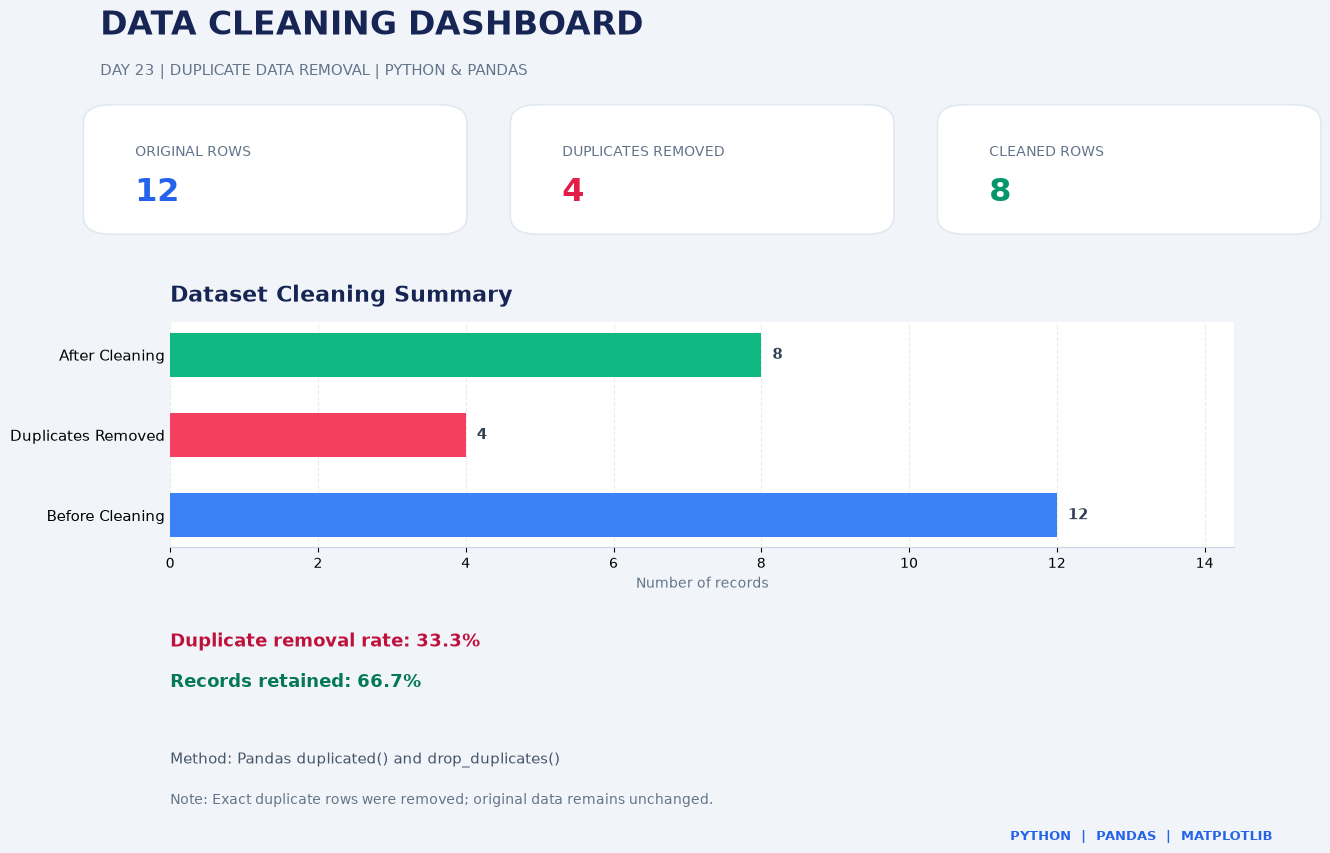

In [8]:
from matplotlib.patches import FancyBboxPatch

# Calculate metrics from actual data
before = len(df)
duplicates = int(df.duplicated().sum())
cleaned = len(df.drop_duplicates())
retention = (cleaned / before * 100) if before else 0
removal_rate = (duplicates / before * 100) if before else 0

# Dashboard canvas
fig = plt.figure(figsize=(14, 9), facecolor="#F1F5F9")

fig.text(
    0.07, 0.93, "DATA CLEANING DASHBOARD",
    fontsize=24, fontweight="bold", color="#172554"
)

fig.text(
    0.07, 0.885,
    "DAY 23 | DUPLICATE DATA REMOVAL | PYTHON & PANDAS",
    fontsize=11, color="#64748B"
)

# KPI cards
def add_card(x, title, value, color):
    card = FancyBboxPatch(
        (x, 0.72), 0.25, 0.12,
        boxstyle="round,pad=0.012,rounding_size=0.02",
        transform=fig.transFigure,
        facecolor="white",
        edgecolor="#E2E8F0",
        linewidth=1.2
    )
    fig.patches.append(card)

    fig.text(
        x + 0.025, 0.795, title,
        fontsize=10, color="#64748B"
    )

    fig.text(
        x + 0.025, 0.745, value,
        fontsize=23, fontweight="bold", color=color
    )

add_card(0.07, "ORIGINAL ROWS", f"{before}", "#2563EB")
add_card(0.375, "DUPLICATES REMOVED", f"{duplicates}", "#E11D48")
add_card(0.68, "CLEANED ROWS", f"{cleaned}", "#059669")

# Bar chart
ax = fig.add_axes([0.12, 0.36, 0.76, 0.25])
ax.set_facecolor("white")

labels = ["Before Cleaning", "Duplicates Removed", "After Cleaning"]
values = [before, duplicates, cleaned]
bar_colors = ["#3B82F6", "#F43F5E", "#10B981"]

bars = ax.barh(labels, values, color=bar_colors, height=0.55)

ax.set_title(
    "Dataset Cleaning Summary",
    loc="left", fontsize=16,
    fontweight="bold", color="#172554", pad=15
)

ax.set_xlabel("Number of records", color="#64748B")
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")
ax.tick_params(axis="y", length=0, labelsize=11)

ax.set_xlim(0, max(values + [1]) * 1.2)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value}",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#334155"
    )

# Results panel
fig.text(
    0.12, 0.25,
    f"Duplicate removal rate: {removal_rate:.1f}%",
    fontsize=13, fontweight="bold", color="#BE123C"
)

fig.text(
    0.12, 0.205,
    f"Records retained: {retention:.1f}%",
    fontsize=13, fontweight="bold", color="#047857"
)

fig.text(
    0.12, 0.12,
    "Method: Pandas duplicated() and drop_duplicates()",
    fontsize=11, color="#475569"
)

fig.text(
    0.12, 0.075,
    "Note: Exact duplicate rows were removed; original data remains unchanged.",
    fontsize=10, color="#64748B"
)

fig.text(
    0.72, 0.035,
    "PYTHON  |  PANDAS  |  MATPLOTLIB",
    fontsize=9, color="#2563EB", fontweight="bold"
)

plt.savefig(
    "duplicate_removal_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()